In [1]:
import os
import cv2
import pyewts
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from glob import glob
from natsort import natsorted
from Utils import get_lines_from_page, create_dir, binarize_line, pad_image2, prepare_ocr_image2

from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference, KerasInference
from evaluate import load

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4, axis="off"):
    plt.figure(figsize=(18, 9))
    plt.axis(axis)
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)


In [26]:
layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [28]:
models_path = "Models/OCRModels"
dataset = "GlomanThang"
chkpt_path = "2024_1_26_9_19"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

In [29]:
data_root = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v25"
#data_root = "C:/Users/Eric/Downloads/W3CN636"
#image_path = data_root
images = natsorted(glob(f"{data_root}/*.jpg"))

print(f"Images: {len(images)}")

Images: 612


I2KG2290550004


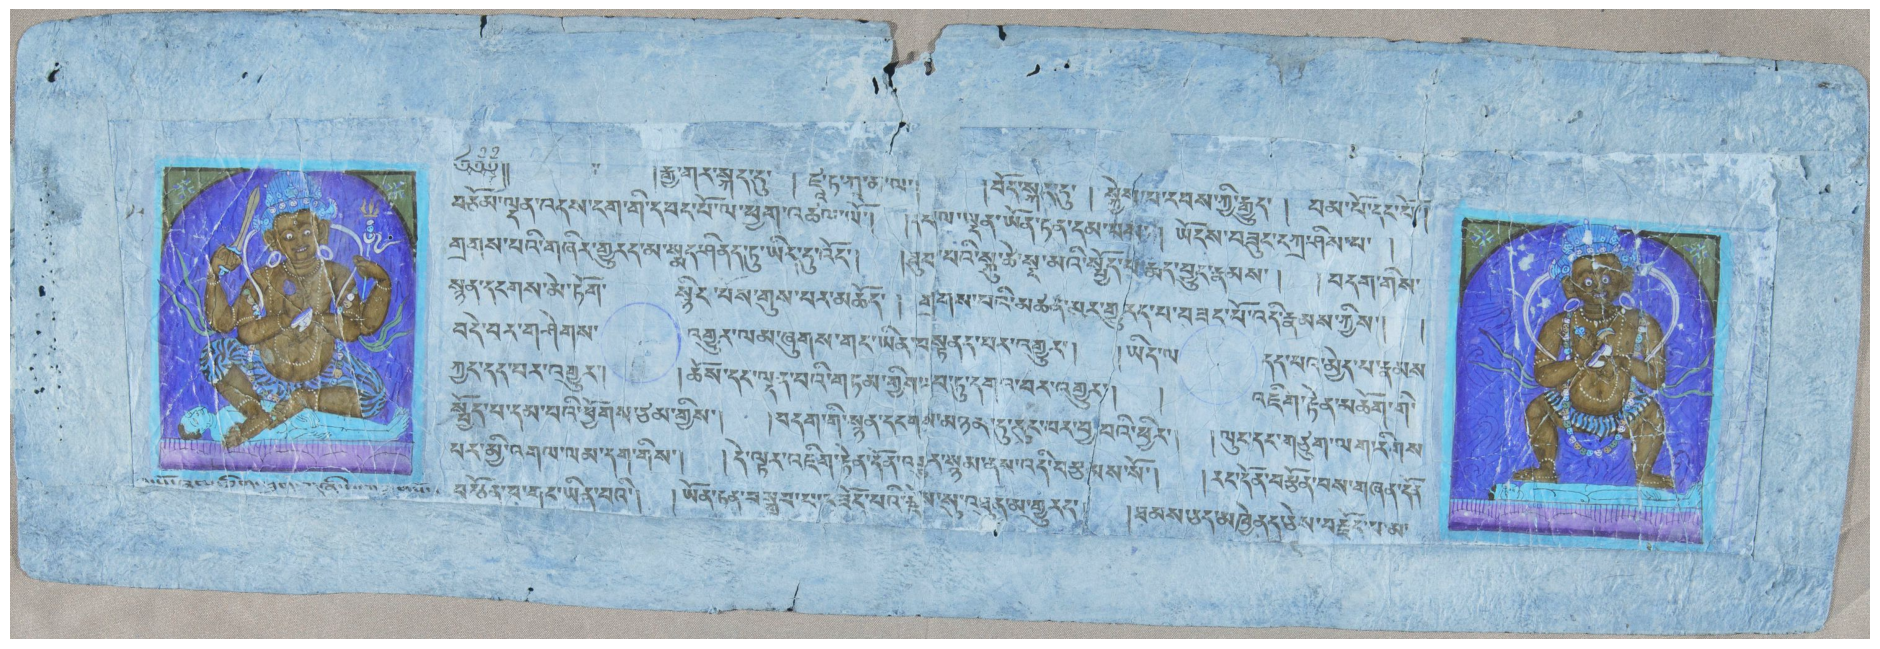

In [30]:
idx = 1
test_image_name = os.path.basename(images[idx]).split(".")[0]
print(test_image_name)
test_image = cv2.imread(images[idx])

show_image(test_image)

In [31]:
prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(test_image, 0)
line_images = [binarize_line(x, adaptive=True) for x in line_images]

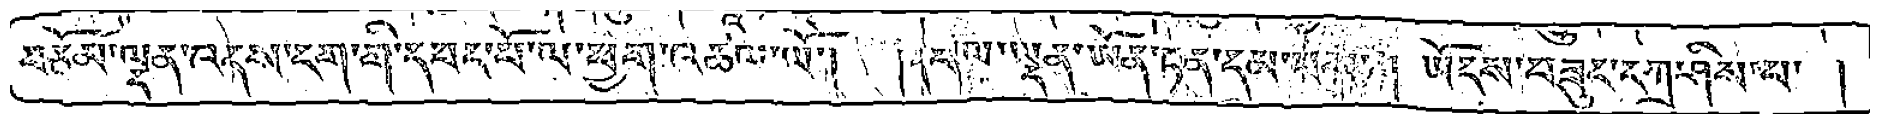

In [32]:
show_image(line_images[1])

In [33]:
np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in line_images]
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)

(22, 1, 80, 2000)


In [35]:
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)

@//rgya gar skad du /dzA ta A ma la //phog skan du /skyes pa dms kyi rgyud /bam po dang 
bcom ldan 'das ngag gi dbang po la phyag 'tshal lo //dpal ldan yon tan dam /yongs bzung dgr shis pa 
grags pa'i gzhir gyurd ma smad shind tu yid du 'ong //thub pa'i sku tshe snga ma'i spyod chad phyung rnams //bdag gi
/
snyan dngags me tog snying pos gus par mchod //grogs pa'i mtshan par gyurd pa bzang po 'di rnams kyis 
bde bar gshegs 'gyur lam zhugs gang yin bstand par 'gyur //yid ladad pa' myed pa rnams 
kyang ngan par 'gyur //chos dang ldan pa'i gtam gyis rab tu dga' bar 'gyur /'jig rten mchog 
spyod pa dam pa'i phyogs tsam gyis //bdag gi snyan dngagis mnyan du cung par bya ba'i phyir //lung dan gtsug lag rig 
yi 'gs pa b dag gas de ltar 'jig nyid gh na ltar bya ba ni mi 'ini bgol g-i /'di did bzhi 
//coM g a ao @/
r-i ba  ' gy-i   'i chis a mchos l pa gang yin ba'i //yon tan la sgram par 'gyod pa'i snos su 'gurn ma gyurd //stams cad mkhyend ces bzod pa 


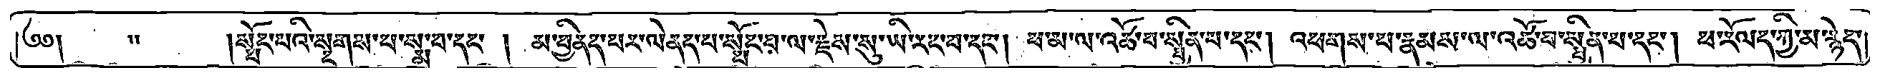

In [10]:
show_image(line_images[0])

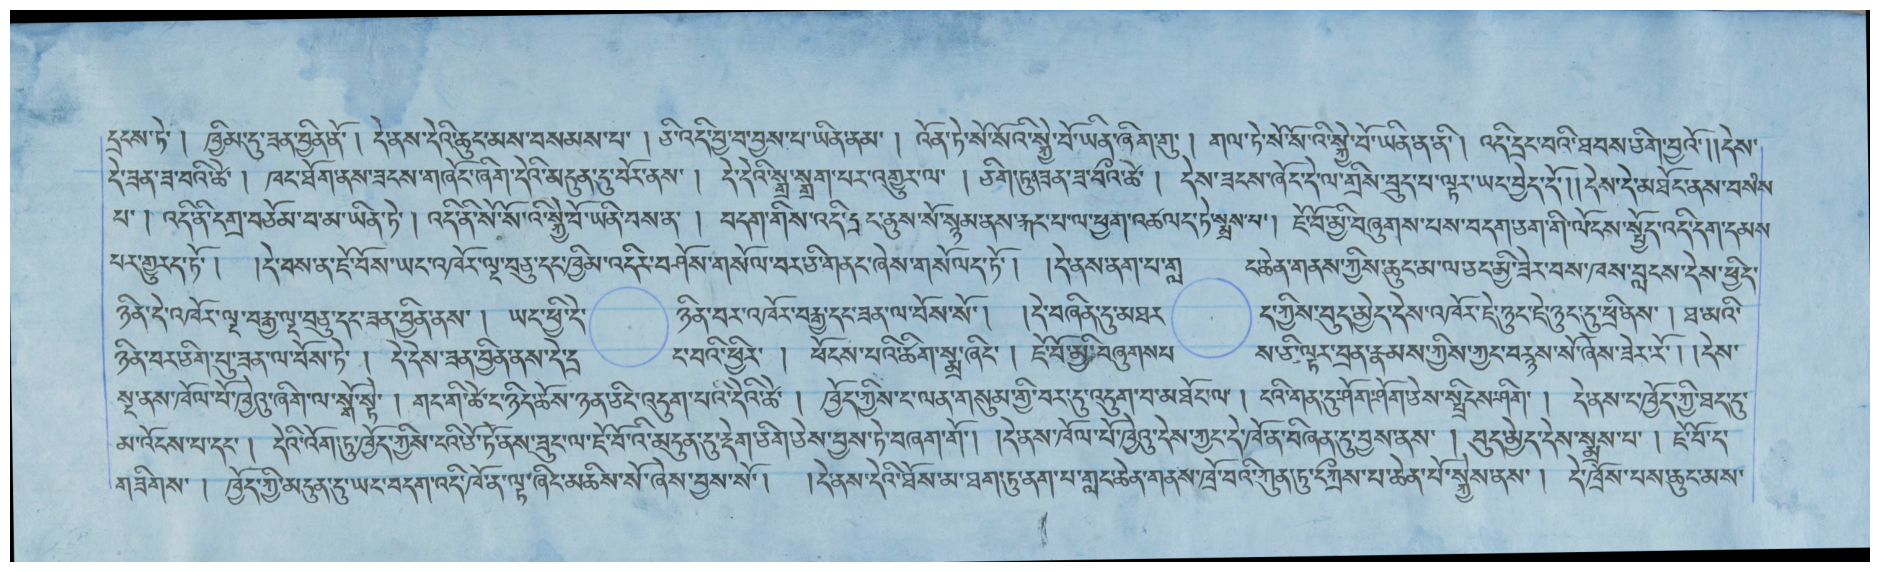

In [21]:
show_image(rotated_image)

In [13]:
from Utils import build_xml_document

converter = pyewts.pyewts()

In [14]:
output_dir = os.path.join(data_root, "predictions_jan2024")
create_dir(output_dir)
xml_out = os.path.join(output_dir,"page")
create_dir(xml_out)

for idx, image_path in tqdm(enumerate(images), total=len(images)):
    image_name = os.path.basename(images[idx]).split(".")[0]
    image = cv2.imread(images[idx])
    prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(image, 0)


    if len(line_images) > 0:
        line_images = [tweak_image(x) for x in line_images]
        np_img_batch = [
                    prepare_ocr_image2(
                        x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                    ) for x in line_images]
        np_img_batch = np.array(np_img_batch)

        predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
        predicted_text = [converter.toUnicode(x) for x in predicted_text]

        xml_results = build_xml_document(rotated_image, image_name, bbox, sorted_contours, predicted_text)

        with open(f"{xml_out}/{image_name}.xml", "w", encoding="utf-8") as f:
            f.write(xml_results)

100%|██████████| 612/612 [17:06<00:00,  1.68s/it]
